# BÁO CÁO THỰC HÀNH 2
## Transfer Learning với VGG16 và DenseNet121

**Học phần:** Mạng nơ-ron tích chập và học chuyển giao  
**Bài toán:** Phân loại 37 giống chó/mèo trên Oxford-IIIT Pet  
**Nhóm:** Nhóm 10  
**Bản HTML trình bày:** [Mở báo cáo HTML](./bao_cao_thuc_hanh_2_transfer_learning.html)  

---

### Tóm tắt

Báo cáo trình bày quy trình từ chuẩn bị dữ liệu, tiền xử lý ảnh, xây dựng mô hình học chuyển giao, huấn luyện và chọn checkpoint, đến đánh giá kết quả. Nhóm sử dụng VGG16 và DenseNet121 với trọng số pretrained ImageNet. Trong các cấu hình đã chạy, **DenseNet121 với learning rate 0.001 và batch size 16 đạt test accuracy 91.31%**, cao hơn VGG16 2.51 điểm phần trăm trong lần thực nghiệm này.

> Notebook này vừa là tài liệu báo cáo, vừa có các ô mã để kiểm tra dữ liệu, nạp một batch và đọc lại kết quả đã lưu. Việc huấn luyện đầy đủ được để ở một ô lệnh riêng vì có thể mất nhiều thời gian.

## 1. Mục tiêu và bài toán

Mục tiêu là xây dựng bộ phân loại ảnh gồm **37 lớp giống chó và mèo**. Thay vì khởi tạo và huấn luyện toàn bộ mạng từ đầu, nhóm tận dụng các đặc trưng tổng quát mà mạng đã học từ ImageNet, thay lớp phân loại cuối để khớp với số lớp mới, sau đó huấn luyện phần phân loại.

Các câu hỏi thực nghiệm chính:

1. Hai kiến trúc VGG16 và DenseNet121 hoạt động ra sao trên cùng bộ dữ liệu?
2. Learning rate 0.01 và 0.001 ảnh hưởng thế nào trong các lần chạy đã thực hiện?
3. Mô hình nào đạt kết quả tốt hơn trên test sau khi được chọn bằng validation?

**Giới hạn thiết kế:** batch size được giữ cố định ở 16 trong CSV hiện có. Vì vậy báo cáo không kết luận về ảnh hưởng của batch size 16 so với 32.

## 2. Dữ liệu Oxford-IIIT Pet

Bộ dữ liệu có 37 lớp, được nhóm tổ chức theo cấu trúc `ImageFolder`. Tập train và validation được tách phân tầng từ split `trainval` chính thức theo tỷ lệ 80/20; split test chính thức được giữ riêng để đánh giá cuối cùng.

| Tập | Số ảnh | Vai trò |
|---|---:|---|
| Train | 2,941 | Cập nhật trọng số mô hình |
| Validation | 739 | Theo dõi quá trình học và chọn checkpoint/cấu hình |
| Test | 3,669 | Đánh giá cấu hình được chọn bằng validation |

![Một số ảnh thuộc Oxford-IIIT Pet](../bao_cao_hinh_anh/anh_mau_oxford_pet.png)

Hình minh họa các giống khác nhau trong bài toán. Tên thư mục lớp được dùng làm nhãn; cả ba split phải có cùng tên lớp và cùng thứ tự lớp để chỉ số nhãn nhất quán.

### Phân bố dữ liệu theo split

![Số lượng ảnh trong từng split](../bao_cao_hinh_anh/phan_bo_dataset.png)

Các số trên biểu đồ khớp với số ảnh của ba split trong báo cáo kiểm tra. Train/validation được dùng trong phát triển mô hình; test không được dùng để chọn siêu tham số. Kiểm tra checksum SHA-256 của nhóm không phát hiện ảnh byte-identical giữa các split; phương pháp này không phát hiện ảnh đã nén lại hoặc ảnh gần giống về nội dung.

In [ ]:
# Tìm thư mục gốc của dự án dù notebook được mở từ thư mục notebooks/ hay từ repo.
from pathlib import Path

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "main.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy src/main.py; hãy mở notebook trong repo BAI_E2.")

DATA_DIR = ROOT / "dataset"
print(f"Thư mục dự án: {ROOT}")
print(f"Thư mục dữ liệu: {DATA_DIR}")

In [ ]:
# Kiểm tra nhanh số lớp, số ảnh và tính nhất quán tên lớp giữa các split.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
split_classes = {}
split_counts = {}

for split in ("train", "val", "test"):
    split_dir = DATA_DIR / split
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Thiếu thư mục dữ liệu: {split_dir}")
    classes = sorted(path.name for path in split_dir.iterdir() if path.is_dir())
    split_classes[split] = classes
    split_counts[split] = sum(
        1 for path in split_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"{split:>5}: {split_counts[split]:>5} ảnh | {len(classes):>2} lớp")

if not (split_classes["train"] == split_classes["val"] == split_classes["test"]):
    raise ValueError("Tên lớp giữa train, val và test không đồng nhất.")
print("Các split có cùng danh sách lớp:", len(split_classes["train"]) == 37)

## 3. Tiền xử lý và nạp dữ liệu

Trong [`src/data_loader.py`](../src/data_loader.py), ảnh được đưa về kích thước đầu vào 224×224 và chuẩn hóa theo mean/std của ImageNet để tương thích với trọng số pretrained.

- **Train:** resize 256, random resized crop 224 và lật ngang ngẫu nhiên. Augmentation giúp mô hình không phụ thuộc quá mức vào một cách bố trí ảnh.
- **Train-eval, validation, test:** resize 256, center crop 224 và chuẩn hóa; không dùng augmentation ngẫu nhiên để metric có thể so sánh ổn định.
- **ImageFolder/DataLoader:** đọc ảnh theo thư mục lớp và đóng gói ảnh thành batch.

Phép chuẩn hóa cho từng kênh màu có dạng $x' = (x - \mu) / \sigma$, với $\mu=(0.485, 0.456, 0.406)$ và $\sigma=(0.229, 0.224, 0.225)$.

In [ ]:
# Dùng chính DataLoader của dự án để xác nhận một batch có thể được tạo.
import sys

src_path = str(ROOT / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from data_loader import create_dataloaders

train_loader, train_eval_loader, val_loader, test_loader, class_names = create_dataloaders(
    DATA_DIR, batch_size=16, num_workers=0, seed=42
)
images, labels = next(iter(train_loader))
print("Số lớp:", len(class_names))
print("Shape ảnh trong batch:", tuple(images.shape))
print("Shape nhãn:", tuple(labels.shape))
print("Một vài nhãn:", [class_names[index] for index in labels[:5].tolist()])

Kết quả mong đợi có shape ảnh dạng `[16, 3, 224, 224]` (batch cuối của một epoch có thể ít hơn 16). Trục màu có 3 kênh RGB; nhãn là chỉ số lớp tương ứng với `class_names`.

## 4. Mô hình và học chuyển giao

Phần điều phối lựa chọn mô hình nằm trong [`src/models.py`](../src/models.py); cách cài đặt từng kiến trúc được tách riêng trong [`src/vgg16_model.py`](../src/vgg16_model.py) và [`src/densenet121_model.py`](../src/densenet121_model.py):

- **VGG16:** dùng trọng số ImageNet; thay `classifier[6]` thành lớp tuyến tính có 37 đầu ra. Backbone được đóng băng; chỉ classifier mới được cập nhật theo cấu hình mặc định.
- **DenseNet121:** dùng trọng số ImageNet; thay `classifier` thành lớp tuyến tính có 37 đầu ra. Mặc định backbone được đóng băng và classifier mới được huấn luyện.
- Tùy chọn `--fine-tune-last-block` mở thêm khối đặc trưng cuối để cập nhật. Các kết quả trong CSV hiện tại là cấu hình mặc định, không bật tùy chọn này.

Ở cấu hình mặc định, VGG16 có 151,589 tham số trainable trên tổng 134,412,133; DenseNet121 có 37,925 tham số trainable trên tổng 6,991,781. Đây là số liệu cấu hình được ghi trong báo cáo kiểm tra mô hình của nhóm.

Thay đổi đầu ra từ 1,000 lớp ImageNet sang 37 lớp giúp mô hình dự đoán đúng tập giống chó/mèo. Đóng băng backbone giảm số tham số cần cập nhật; điều này không đồng nghĩa chắc chắn loại bỏ overfitting.

### Sơ đồ quá trình

```text
Oxford-IIIT Pet
      ↓
ImageFolder: train / val / test
      ↓
Resize, crop, augmentation (train), chuẩn hóa ImageNet
      ↓
VGG16 hoặc DenseNet121 pretrained → classifier 37 lớp
      ↓
CrossEntropyLoss + Adam → train theo epoch
      ↓
Validation → lưu checkpoint có val loss thấp nhất / early stopping
      ↓
Chọn cấu hình theo validation → đánh giá test
      ↓
TensorBoard, checkpoint và results.csv
```

## 5. Huấn luyện, validation và chọn mô hình

Vòng lặp trong [`src/engine.py`](../src/engine.py) thực hiện các bước sau cho mỗi batch:

1. Đưa ảnh và nhãn lên CPU/GPU đang dùng.
2. Tính logits bằng mô hình và tính **CrossEntropyLoss** giữa logits với nhãn thật.
3. Ở pha train: xóa gradient cũ, lan truyền ngược loss và cập nhật tham số bằng **Adam**.
4. Tính loss trung bình theo số mẫu và accuracy cho toàn epoch.

Sau mỗi epoch, chương trình đo train-eval (train với transform cố định) và validation. Checkpoint có validation loss thấp nhất được lưu. **Early stopping** dừng nếu validation loss không cải thiện trong 3 epoch liên tiếp; số epoch tối đa là 5 ở các lần chạy báo cáo. Trong tuning, cấu hình được chọn theo validation loss. Test chỉ được chạy cho cấu hình đã chọn của mỗi kiến trúc, tránh dùng test để điều chỉnh mô hình.

Metric được ghi vào TensorBoard và tổng hợp trong `outputs/reduced-experiments/results.csv`.

In [ ]:
# Lệnh tái chạy ma trận thí nghiệm đầy đủ (tối đa 8 lần huấn luyện).
# Bỏ dấu # và chạy riêng ô này khi đã cài requirements và sẵn sàng chờ huấn luyện.
# !python src/main.py --data-dir dataset --epochs 5 --patience 3 --batch-size 16 --tune --output-dir outputs/reduced-experiments

Lệnh trên dùng hai kiến trúc mặc định, hai learning rate (`0.01`, `0.001`) và hai batch size mặc định (`16`, `32`). Tuy nhiên, **kết quả đang có trong CSV được tạo từ bốn cấu hình, batch size 16 cố định**; không được diễn giải CSV như thể đã chạy batch size 32. Các lần chạy dùng seed 42, giới hạn 5 epoch và patience 3.

Muốn xem đường cong trong TensorBoard sau khi chạy:

```powershell
python -m tensorboard.main --logdir .\outputs\reduced-experiments
```

Accuracy được lưu ở dạng tỷ lệ từ 0 đến 1; ví dụ `0.913` tương đương khoảng 91.3%.

## 6. Kết quả thực nghiệm

Bảng dưới được đọc trực tiếp từ CSV của nhóm. Ô test để trống có nghĩa cấu hình đó không được chọn bằng validation và không được đánh giá trên test; đây là chủ đích của quy trình, không phải dữ liệu bị thiếu cần tự suy đoán.

In [ ]:
import csv

RESULTS_PATH = ROOT / "outputs" / "reduced-experiments" / "results.csv"
if not RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy file kết quả: {RESULTS_PATH}")

with RESULTS_PATH.open("r", encoding="utf-8-sig", newline="") as results_file:
    results = list(csv.DictReader(results_file))

columns = ("Model", "LR", "Batch", "Epoch tốt nhất", "Val loss", "Val acc", "Test acc", "Chọn theo val")
print(" | ".join(columns))
print(" | ".join("---" for _ in columns))
for row in results:
    test_accuracy = f"{float(row['test_accuracy']) * 100:.2f}%" if row["test_accuracy"] else "—"
    selected = "Có" if row["selected_by_validation"].lower() == "true" else "Không"
    values = (
        row["model"], row["learning_rate"], row["batch_size"], row["best_epoch"],
        f"{float(row['best_validation_loss']):.4f}",
        f"{float(row['validation_accuracy_at_best_loss']) * 100:.2f}%",
        test_accuracy, selected,
    )
    print(" | ".join(values))

### Nhìn nhanh validation và kết quả test

Biểu đồ dưới đây được tạo từ chính `results.csv`: validation accuracy càng cao càng tốt, validation loss càng thấp càng tốt. Màu xanh lá đánh dấu cấu hình được chọn theo validation; biểu đồ test chỉ có hai cấu hình đã chọn, vì các cấu hình còn lại không chạy test.

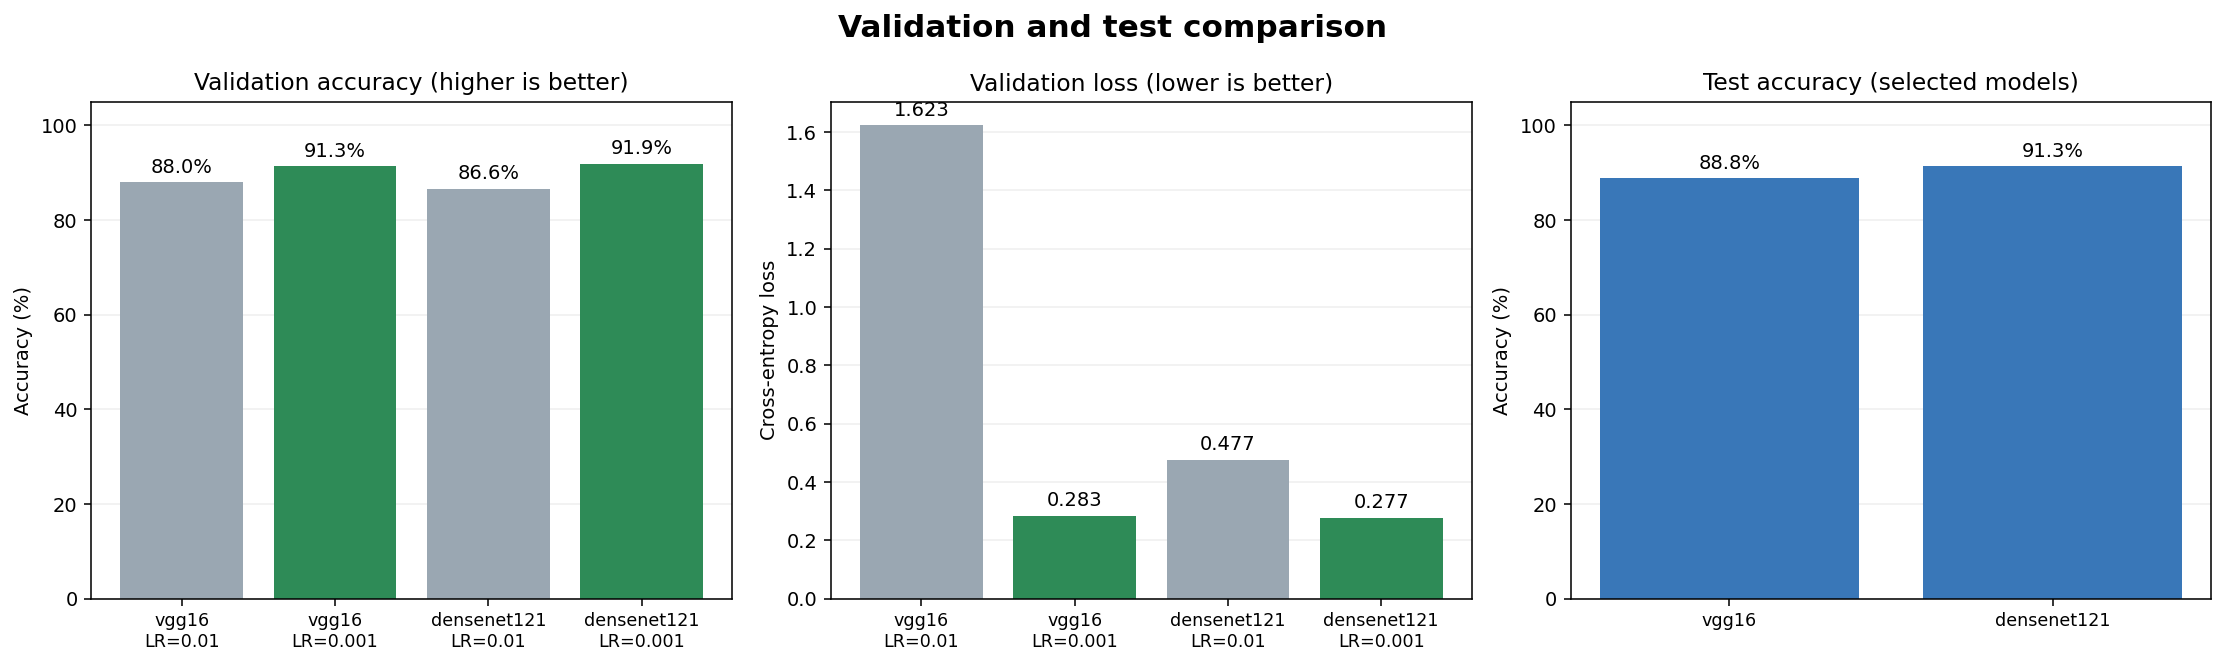

In [ ]:
import matplotlib.pyplot as plt

labels = [f"{row['model']}\nLR={float(row['learning_rate']):g}" for row in results]
selected_flags = [row["selected_by_validation"].lower() == "true" for row in results]
bar_colors = ["#2e8b57" if selected else "#9aa7b2" for selected in selected_flags]
validation_accuracies = [float(row["validation_accuracy_at_best_loss"]) * 100 for row in results]
validation_losses = [float(row["best_validation_loss"]) for row in results]
selected_results = [row for row in results if row["test_accuracy"]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
fig.suptitle("Validation and test comparison", fontsize=16, fontweight="bold")

bars = axes[0].bar(labels, validation_accuracies, color=bar_colors)
axes[0].set_title("Validation accuracy (higher is better)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 105)
axes[0].bar_label(bars, fmt="%.1f%%", padding=3)

bars = axes[1].bar(labels, validation_losses, color=bar_colors)
axes[1].set_title("Validation loss (lower is better)")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].bar_label(bars, fmt="%.3f", padding=3)

test_labels = [row["model"] for row in selected_results]
test_accuracies = [float(row["test_accuracy"]) * 100 for row in selected_results]
bars = axes[2].bar(test_labels, test_accuracies, color="#3977b8")
axes[2].set_title("Test accuracy (selected models)")
axes[2].set_ylabel("Accuracy (%)")
axes[2].set_ylim(0, 105)
axes[2].bar_label(bars, fmt="%.1f%%", padding=3)

for axis in axes:
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
    axis.tick_params(axis="x", labelrotation=0, labelsize=9)
fig.tight_layout()
plt.show()

**Cách đọc biểu đồ:**

- Hai ô bên trái so sánh cả bốn lần chạy trên validation. DenseNet121 với LR 0.001 được chọn vì có validation loss thấp nhất trong các cấu hình DenseNet121; VGG16 cũng chọn LR 0.001 theo cùng tiêu chí.
- Ô bên phải chỉ hiển thị test accuracy của hai cấu hình được chọn. DenseNet121 cao hơn VGG16 trong lần chạy hiện tại.
- Accuracy và loss là hai góc nhìn bổ sung: accuracy thể hiện tỷ lệ dự đoán đúng; loss còn phản ánh mức độ tự tin của dự đoán sai/đúng.

Validation là tập dùng để ra quyết định trong quá trình phát triển; test là bước kiểm tra cuối. Vì vậy không đưa các cấu hình chưa chọn lên biểu đồ test và không chọn mô hình dựa trên test.

### Tóm tắt kết quả được chọn

| Kiến trúc | Learning rate | Batch size | Validation loss | Validation accuracy | Test loss | Test accuracy |
|---|---:|---:|---:|---:|---:|---:|
| VGG16 | 0.001 | 16 | 0.2831 | 91.34% | 0.3450 | 88.80% |
| DenseNet121 | 0.001 | 16 | 0.2767 | 91.88% | 0.3236 | 91.31% |

![Biểu đồ demo DenseNet121 sau một epoch](../bao_cao_hinh_anh/ket_qua_demo_1_epoch.png)

> **Lưu ý:** ảnh trên là biểu đồ demo riêng sau **1 epoch**, không phải biểu đồ so sánh cuối cùng của toàn bộ thí nghiệm. Kết quả chính thức trong phần nhận xét lấy từ `results.csv` (checkpoint tốt nhất được chọn bằng validation).

### Nhận xét và giải thích

- Trong các lần chạy đã thực hiện, learning rate **0.001** cho validation loss thấp hơn learning rate 0.01 ở cả VGG16 và DenseNet121. Đây là kết quả quan sát trên lần chạy/split này, không phải kết luận phổ quát cho mọi dữ liệu.
- DenseNet121 đạt test accuracy **91.31%**, cao hơn VGG16 (**88.80%**) khoảng **2.51 điểm phần trăm**; test loss cũng thấp hơn (0.3236 so với 0.3450).
- Validation accuracy của hai mô hình khá gần nhau (91.88% và 91.34%). Chênh lệch train-eval và validation accuracy tại checkpoint tốt nhất lần lượt khoảng 4.07 điểm phần trăm với DenseNet121 và 3.80 điểm phần trăm với VGG16. Đây là khoảng cách tổng quát hóa cần theo dõi, không đủ để khẳng định mô hình hoàn toàn không overfit.
- DenseNet121 có ít tham số tổng thể hơn đáng kể trong cấu hình này, nhưng nhóm chưa đo thời gian/bộ nhớ thực tế một cách đối chứng nên không kết luận mô hình nào chạy nhanh hơn.

**Kết luận thực nghiệm:** với Oxford-IIIT Pet, seed và các cấu hình hiện có, DenseNet121 tại learning rate 0.001 là mô hình tốt nhất trong hai mô hình được so sánh. Test set chỉ được sử dụng cho hai cấu hình đã chọn bằng validation.

## 7. Hạn chế và hướng cải thiện

1. Batch size chỉ được giữ ở 16 trong kết quả hiện tại; cần chạy thêm batch size 32 để trả lời đầy đủ câu hỏi về siêu tham số.
2. Kết quả dựa trên một seed và một cách chia dữ liệu; có thể chạy nhiều seed hoặc k-fold nếu tài nguyên cho phép để đánh giá độ ổn định.
3. Thử nghiệm chạy tối đa 5 epoch và trên môi trường CPU theo tài liệu dự án; thời gian huấn luyện và khả năng cải thiện khi fine-tune sâu hơn chưa được khảo sát đầy đủ.
4. So sánh checksum không phát hiện ảnh trùng đã được đổi định dạng hoặc ảnh gần giống; có thể bổ sung perceptual hash nếu cần kiểm tra sâu hơn.
5. Có thể phân tích confusion matrix và precision/recall theo từng lớp để biết các giống nào thường bị nhầm lẫn.

## 8. Kết luận báo cáo

Nhóm đã xây dựng pipeline phân loại ảnh 37 giống chó/mèo bằng transfer learning với VGG16 và DenseNet121. Dữ liệu được tách train/validation/test, tiền xử lý phù hợp với ImageNet, augmentation chỉ áp dụng ở train, và checkpoint được lựa chọn dựa trên validation loss trước khi đánh giá test. Trong các cấu hình đã chạy, DenseNet121 đạt kết quả test tốt hơn VGG16. Các kết luận được giới hạn trong phạm vi một lần thực nghiệm và batch size 16; cần thêm lần chạy để khẳng định độ ổn định và so sánh batch size.

### Tài liệu/mã nguồn liên quan

- [`README.md`](../README.md) — hướng dẫn tổng quan và cách chạy dự án.
- [`src/data_loader.py`](../src/data_loader.py) — tiền xử lý và DataLoader.
- [`src/models.py`](../src/models.py) — điều phối mô hình và đếm tham số.
- [`src/vgg16_model.py`](../src/vgg16_model.py) — triển khai VGG16.
- [`src/densenet121_model.py`](../src/densenet121_model.py) — triển khai DenseNet121.
- [`src/engine.py`](../src/engine.py) — huấn luyện và đánh giá theo epoch.
- [`src/main.py`](../src/main.py) — điều phối thí nghiệm, early stopping và lưu kết quả.
- [`docs/data_model_validation.md`](../docs/data_model_validation.md) — chi tiết kiểm tra dữ liệu và mô hình.